In [8]:
# Unsupervised Learning:
    # - kmeans
    # - heirarchial

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [3]:
df = pd.read_csv(r"botanical_garden_visitors.csv")
df.head()

,Visit_Duration_Min,Exhibits_Visited,Cafe_Spending_INR,Gift_Shop_Spending_INR,Guided_Tour,Group_Size,Visits_Per_Year
0,243,11,101,162,1,2,4.4
1,104,6,150,272,0,4,0.3
2,173,10,1127,535,1,1,5.2
3,229,13,196,184,0,1,4.3
4,59,4,62,69,0,2,1.2


In [4]:
X = df.copy()
X.head()

,Visit_Duration_Min,Exhibits_Visited,Cafe_Spending_INR,Gift_Shop_Spending_INR,Guided_Tour,Group_Size,Visits_Per_Year
0,243,11,101,162,1,2,4.4
1,104,6,150,272,0,4,0.3
2,173,10,1127,535,1,1,5.2
3,229,13,196,184,0,1,4.3
4,59,4,62,69,0,2,1.2


In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
x_scaled_df = pd.DataFrame(X_scaled, columns = X.columns)
x_scaled_df.head()

,Visit_Duration_Min,Exhibits_Visited,Cafe_Spending_INR,Gift_Shop_Spending_INR,Guided_Tour,Group_Size,Visits_Per_Year
0,1.573991,0.670275,-0.767764,-0.355680,1.168730,-0.276487,0.212523
1,-0.515750,-0.592171,-0.571821,0.007376,-0.855629,1.124628,-1.442138
2,0.521603,0.417785,3.335048,0.875409,1.168730,-0.977044,0.535384
3,1.363514,1.175253,-0.387874,-0.283069,-0.855629,-0.977044,0.172165
4,-1.192285,-1.097150,-0.923719,-0.662628,-0.855629,-0.276487,-1.078919


In [9]:
# 1. Choose the no of clusters
# 2. Centroids - centers of k clusters
# 3. Calculate Distance
# 4. Update the cluster centers
# 5. Repeat the process
# 6. Final Clusters

In [10]:
kmean = KMeans(
    n_clusters = 4,
    random_state = 42,
    n_init = 10
)

In [11]:
kmeans_labels = kmean.fit_predict(X_scaled)
kmeans_labels

array([3, 2, 1, ..., 3, 2, 3], shape=(1500,), dtype=int32)

In [12]:
df["Kmeans_Cluster"] = kmeans_labels
df.head()

,Visit_Duration_Min,Exhibits_Visited,Cafe_Spending_INR,Gift_Shop_Spending_INR,Guided_Tour,Group_Size,Visits_Per_Year,Kmeans_Cluster
0,243,11,101,162,1,2,4.4,3
1,104,6,150,272,0,4,0.3,2
2,173,10,1127,535,1,1,5.2,1
3,229,13,196,184,0,1,4.3,3
4,59,4,62,69,0,2,1.2,0


In [13]:
# Counting the number of visitors in each category
df["Kmeans_Cluster"].value_counts().sort_index()

Kmeans_Cluster
0    450
1    232
2    459
3    359
Name: count, dtype: int64

Text(0, 0.5, 'Cafe Spending in INR')

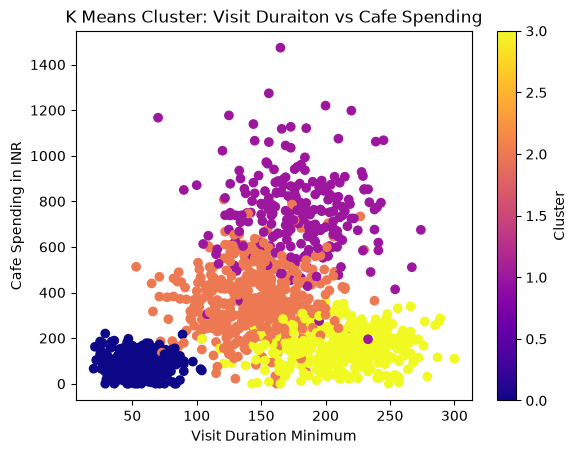

In [17]:
plt.scatter(
    df["Visit_Duration_Min"],
    df["Cafe_Spending_INR"],
    c = df["Kmeans_Cluster"],
    cmap = "plasma"
)
plt.colorbar(label = "Cluster")
plt.title("K Means Cluster: Visit Duraiton vs Cafe Spending")
plt.xlabel("Visit Duration Minimum")
plt.ylabel("Cafe Spending in INR")

In [18]:
# Evaluation Metrics:
# Inertia - Measures how close data points are to centroids
# Silhoutte Scores - Measures how well our clusters are seperated

In [25]:
k_values = range(1, 11)
inertia_values = []

for k in k_values:
    model = KMeans(
        n_clusters = k,
        random_state = 42,
        n_init = 10
    )
    model.fit(X_scaled)
    inertia_values.append(model.inertia_)

for k, inertia in zip(k_values, inertia_values):
    print("K =", k, "- Inertia = ", round(inertia, 2))

K = 1 - Inertia =  10500.0
K = 2 - Inertia =  6597.01
K = 3 - Inertia =  4695.52
K = 4 - Inertia =  3078.33
K = 5 - Inertia =  2654.73
K = 6 - Inertia =  2325.32
K = 7 - Inertia =  2175.34
K = 8 - Inertia =  2063.71
K = 9 - Inertia =  1960.73
K = 10 - Inertia =  1870.09


In [27]:
# WCSS(inertia) - Within Cluster Sum of Squares

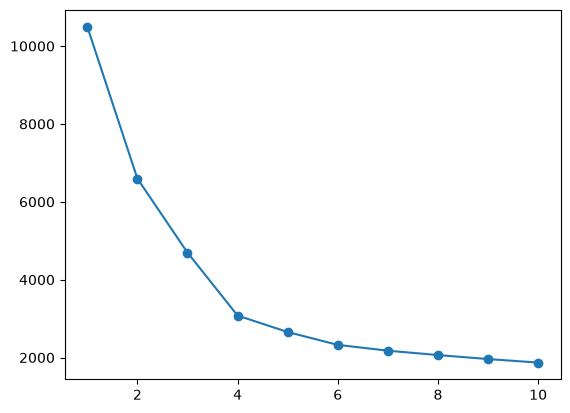

In [30]:
plt.plot(k_values, inertia_values, marker = "o")